In [1]:
import matplotlib.pyplot as plt 
import pandas as pd
from stimuli_effect_identification import dataset_simulation

/home/aubouinb/Nextcloud2/Code/PAS_vs_vitalDB/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data_measure = pd.read_csv('data/database.csv')


In [3]:
# data_measure = data_measure.query('caseid < 600')

In [4]:
data_measure.rename(columns={'opstart': 'surgery_time'}, inplace=True)
data_measure.intubation_time = (data_measure.intubation_time - 2*60).clip(0, 6000) # from end to start of intubation
data_measure['Propofol'] = data_measure['Propofol']*20/3600
data_measure['Remifentanil'] = data_measure['Remifentanil']*20/3600
# data_measure = data_measure.query('caseid < 600')

In [5]:
(data_measure.intubation_time - 2*60).clip(0, 600)

0         118
1         118
2         118
3         118
4         118
         ... 
688303    248
688304    248
688305    248
688306    248
688307    248
Name: intubation_time, Length: 688308, dtype: int64

In [6]:
# param_hemo = {
#     'int_hr': -0.097,
#     'fb': -0.5,
#     'emax_propo_tpr': -0.03,
# }
# data_simu = dataset_simulation(
#     data_measure,
#     bar=True,
#     param_hemo=param_hemo,
# )

data_simu = pd.read_csv('data/simulated_vitaldb.csv')

In [7]:
data_simu = pd.merge(data_simu, data_measure[['caseid', 'Time', 'surgery_time', 'intubation_time']], on=['caseid', 'Time'])

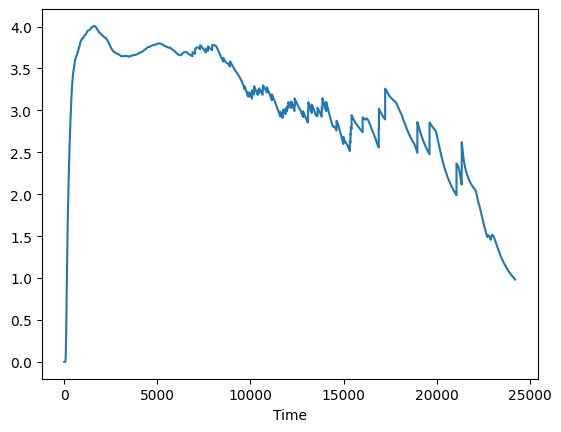

In [8]:
data_simu.groupby('Time')['x_propo_4'].mean().plot()
plt.show()

In [9]:
data_measure['TPR'] = (data_measure['MAP'] / (data_measure['HR'] * data_measure['SV'])).clip(0, 0.04)

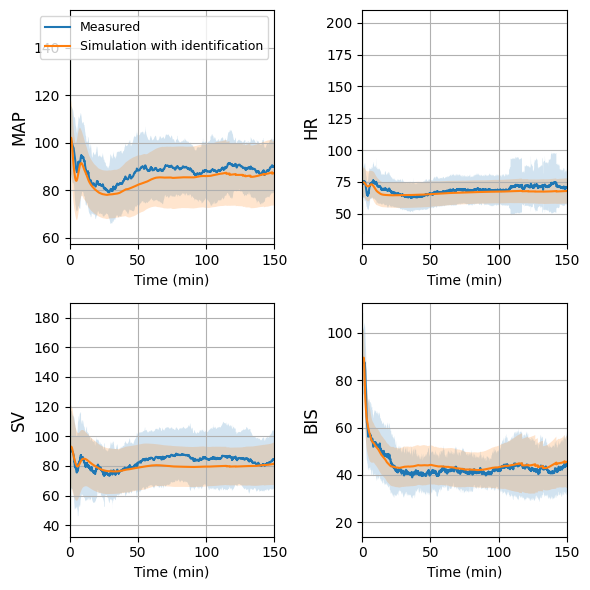

In [10]:
signal_list = ['MAP', 'HR', 'SV', 'BIS']
data_simu['Time_aligned'] = data_simu['Time']# - data_simu['intubation_time']
data_measure['Time_aligned'] = data_measure['Time']# - data_measure['intubation_time']
# data_simu = data_simu.query("(Time_aligned>= -5*60) & (Time_aligned <=20*60)").copy()
# data_measure = data_measure.query("(Time_aligned>= -5*60) & (Time_aligned <=20*60)").copy()
plt.figure(figsize=(6,6))
for i, signal in enumerate(signal_list):
    plt.subplot(2,2,i+1)
    y_measure = data_measure.groupby("Time_aligned")[signal].mean().reset_index()
    y_measure_std = data_measure.groupby("Time_aligned")[signal].std().reset_index()
    y_dist = data_simu.groupby("Time_aligned")[signal].mean().reset_index()
    y_dist_std = data_simu.groupby("Time_aligned")[signal].std().reset_index()
    x = y_measure['Time_aligned'].values/60
    plt.plot(x, y_measure[f"{signal}"].values, label='Measured')
    plt.fill_between(x, y_measure[f"{signal}"].values-y_measure_std[f"{signal}"].values, y_measure[f"{signal}"].values+y_measure_std[f"{signal}"].values
    , alpha = 0.2)
    plt.plot(x, y_dist[signal].values, label='Simulation with identification')
    plt.fill_between(x, y_dist[signal].values-y_dist_std[signal].values, y_dist[signal].values+y_dist_std[signal].values
    , alpha = 0.2)
    y_lim = plt.gca().get_ylim()
    plt.vlines(0,y_lim[0], y_lim[1], 'g')
    plt.grid()
    plt.ylabel(signal, fontsize=12)
    # if signal=='HR':
        # plt.ylim(50,100)
    if i==0:
        plt.legend(fontsize=9)
    plt.xlabel('Time (min)')
    plt.xlim([0,150])
plt.tight_layout()
# plt.savefig('output/dist_intub.pdf', dpi=300)
plt.show()